# Figure 7 — measured ellipticity against JWST: native NISP versus models

The main figure shows the density of per-galaxy ellipticity measured on native
NISP, a single diffusion sample, ResNet and ResNet-D5 against the same quantity
measured on observed JWST F115W, as a hexbin map with a logarithmic colour scale
so both the core and the tails stay visible. Both ellipticity components enter
for every galaxy.
A dashed 1:1 line and a robust Theil-Sen fit over galaxies with |e_JWST| < 0.5
(drawn over that range; an ordinary least-squares fit on the full sample is
pulled below the visual ridge by noise in the JWST axis and by the tails) show directly whether a model brings the relation closer to
1:1 and reduces scatter. Panel annotations give the core fit slope and the full-sample RMSE
about the 1:1 line. Fixed and adaptive moments occupy the two rows.

The companion gain figure keeps the paired spatial-block 95% intervals on the
percentage RMSE reduction, and the companion summary retains interpolation
baselines, mean-of-three diffusion and full-population measurement success.
Earlier layouts are preserved in `exports/` and `revisions/`.

This is a presentation revision of the frozen `cached_shapes_v02` measurements:
all numerical results, populations, masks and checkpoints are unchanged. Native
NISP uses its original grid and validity mask, with the same angular measurement
settings as cached images. Each estimator uses the intersection of successful
JWST, native NISP and all six cached methods: 1,446 objects for fixed moments and
1,498 for adaptive moments, out of 2,118 attempted fields. All comparisons are
conditional on these successful samples; measurement failures remain reported.
These are observed cross-band ellipticities, not PSF-corrected shapes or calibrated
shear. No new inference, training, or test-set access.


Style revision v06: shared scientific figure style, Matisse-inspired method
colors with redundant line patterns and redundant symbols. Frozen inputs, populations, and numerical values
are retained; the previous executed notebook is archived in `revisions/style_before_v01/`.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from IPython.display import display
here=Path.cwd();workspace=here if (here/'figure_utils.py').exists() else here/'paper_figures'
if str(workspace) not in sys.path:sys.path.insert(0,str(workspace))
from figure_utils import ROOT,FIGURES,COLORS,style,read_json,sha,export
%matplotlib inline
style()
VERSION = 'v07'
DATA_VERSION='v02'
path=FIGURES/'inputs'/f'cached_shapes_{DATA_VERSION}.json'
b=read_json(path)
assert b['complete'] and b['local_only']
assert sha(ROOT/b['arrays_path'])==b['arrays_sha256']
with np.load(ROOT/b['arrays_path']) as f:arrays={k:f[k] for k in f.files}
names=b['methods'];labels={'native':'Native NISP','bilinear':'Bilinear','bicubic':'Bicubic','diffusion':'Diffusion (1 sample)',
'diffusion_mean3':'Diffusion (mean of 3)','legacy':'ResNet','direct5':'ResNet-D5'}
colors=COLORS.copy()
print('Attempted:',len(b['object_ids']),'Common across both estimators:',b['cross_estimator_objects'])

from figure_utils import MARKERS, INK, GRID, ESTIMATOR_COLORS, finish_axes


Attempted: 2118 Common across both estimators: 1297


In [2]:
# Common samples, robust core fits and RMSE for every layout.
shown=['native','diffusion','legacy','direct5']
titles={'native':'Native NISP','diffusion':'Diffusion (1 sample)','legacy':'ResNet','direct5':'ResNet-D5'}
LIM=1.0;xx=np.array([-LIM,LIM])
FIT_RANGE=0.5;xf=np.array([-FIT_RANGE,FIT_RANGE])  # robust Theil-Sen fit on |e_JWST|<0.5
from scipy.stats import theilslopes
def core_fit(x,y):
    core=np.abs(x)<FIT_RANGE;slope,intercept,_,_=theilslopes(y[core],x[core]);return slope,intercept,int(core.sum())
samples={};fits={};rmses={}
for case in ['fixed','adaptive']:
    mask=arrays[f'{case}__target__good'].copy()
    for name in names:mask&=arrays[f'{case}__{name}__good']
    assert mask.sum()==b['summaries'][case]['common_successes']
    samples[case]=mask
    x=arrays[f'{case}__target__e'][mask].ravel()
    for name in shown:
        y=arrays[f'{case}__{name}__e'][mask].ravel()
        fits[case,name]=core_fit(x,y)[:2]
        rmses[case,name]=np.sqrt(np.mean((y-x)**2))
        # Same combined-component RMSE as the frozen summary.
        assert np.isclose(rmses[case,name],b['summaries'][case]['methods'][name]['component_rmse']['mean'])
# Shared panel skeleton (1:1, robust core fit, native reference, annotations).
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patheffects as pe
def skeleton(fig,axes,fit_label,native_reference=True):
    for r,(case,ctitle) in enumerate([('fixed','Fixed weighted moments'),('adaptive','Adaptive moments')]):
        for c,name in enumerate(shown):
            ax=axes[r,c];slope,intercept=fits[case,name]
            ax.plot(xx,xx,color='#8C8C8C',lw=1,ls='--',zorder=1)
            if native_reference and name!='native':
                sn,inn=fits[case,'native'];ax.plot(xf,sn*xf+inn,color=colors['native'],lw=1.2,ls=':',zorder=5)
            ax.plot(xf,slope*xf+intercept,color=INK,lw=1.6,zorder=6,
                    path_effects=[pe.Stroke(linewidth=2.6,foreground='white'),pe.Normal()])
            ax.text(.04,.96,f'slope {slope:.2f}\nRMSE {rmses[case,name]:.3f}',transform=ax.transAxes,va='top',ha='left',
                    fontsize=8.5,bbox=dict(boxstyle='square,pad=.2',fc='white',ec='none',alpha=.85),zorder=7)
            ax.set_xlim(-LIM,LIM);ax.set_ylim(-LIM,LIM);ax.set_aspect('equal')
            ax.set_xticks([-1,-.5,0,.5,1],['−1','−0.5','0','0.5','1']);ax.set_yticks([-1,-.5,0,.5,1],['−1','−0.5','0','0.5','1'])
            if r==0:ax.set_title(titles[name],pad=6)
            if r==1:ax.set_xlabel('JWST F115W ellipticity')
        axes[r,0].set_ylabel(f'{ctitle}\nmeasured ellipticity')
        axes[r,0].text(.96,.04,f'{samples[case].sum():,} galaxies\n$e_1$ and $e_2$ pooled',transform=axes[r,0].transAxes,
                       ha='right',va='bottom',fontsize=7.5,color=INK,
                       bbox=dict(fc='white',ec='none',alpha=.9,pad=1.5))
    handles=[Line2D([],[],color='#8C8C8C',ls='--',lw=1,label='1:1'),
             Line2D([],[],color='#1A1A1A',lw=1.6,label=fit_label),
             Line2D([],[],color=colors['native'],ls=':',lw=1.2,label='Native NISP fit (same range)')]
    fig.legend(handles=handles,loc='lower center',ncol=3,frameon=False,bbox_to_anchor=(.54,-.005))
    fig.subplots_adjust(left=.09,right=.99,top=.94,bottom=.135,wspace=.12,hspace=.14)
common_settings=dict(methods=shown,estimators=['fixed','adaptive'],components='e1 and e2 pooled per galaxy',
    fit='Theil-Sen median slope of measured on JWST ellipticity, galaxies with |e_JWST|<0.5',fit_range=[-FIT_RANGE,FIT_RANGE],
    rmse='combined e1/e2 component RMSE about the 1:1 line (full sample)',
    common_objects={case:int(samples[case].sum()) for case in samples},
    fits={f'{case}/{name}':dict(slope=float(s),intercept=float(i)) for (case,name),(s,i) in fits.items()},
    axis_limits=[-LIM,LIM],population=b['population'])
FIT_LABEL='Robust fit, |$e_{\\rm JWST}$| < 0.5'
print('Samples, robust core fits and RMSE ready for',len(fits),'panels')

Samples, robust core fits and RMSE ready for 8 panels


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


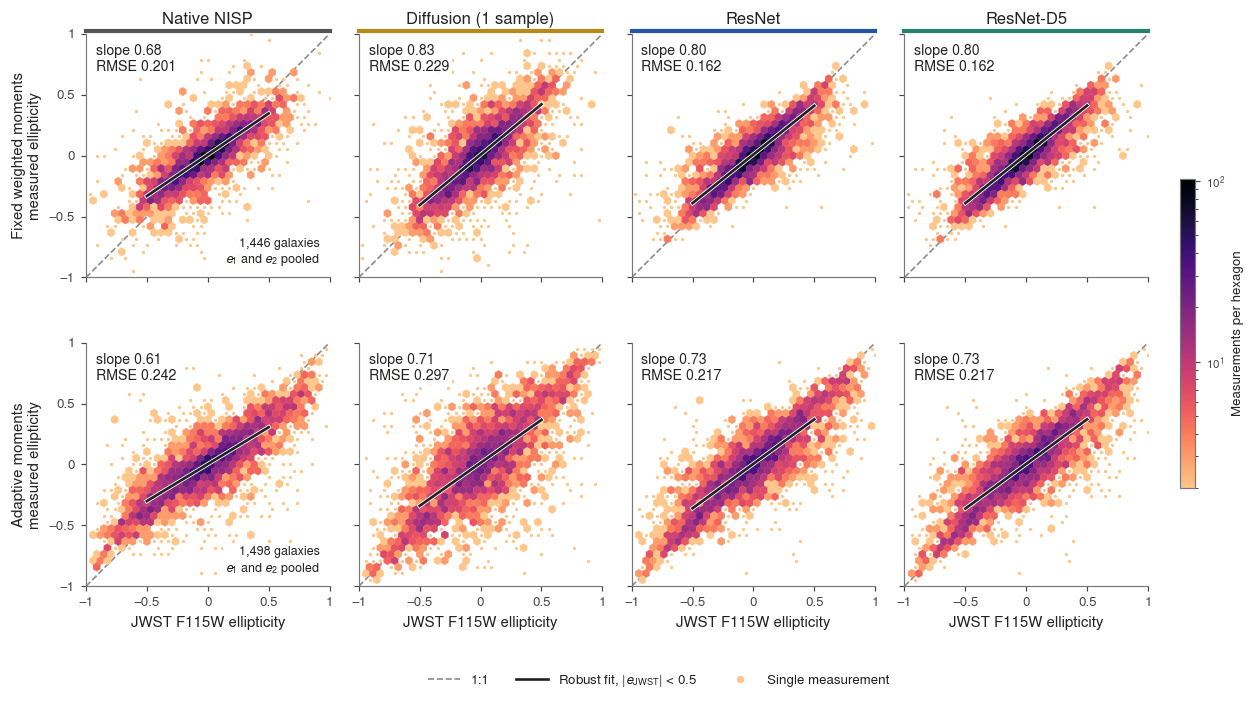

Singleton hexagons drawn as dots: 1204


Exported: fig07_shape_hexbin_v07.pdf, fig07_shape_hexbin_v07.svg, fig07_shape_hexbin_v07.png


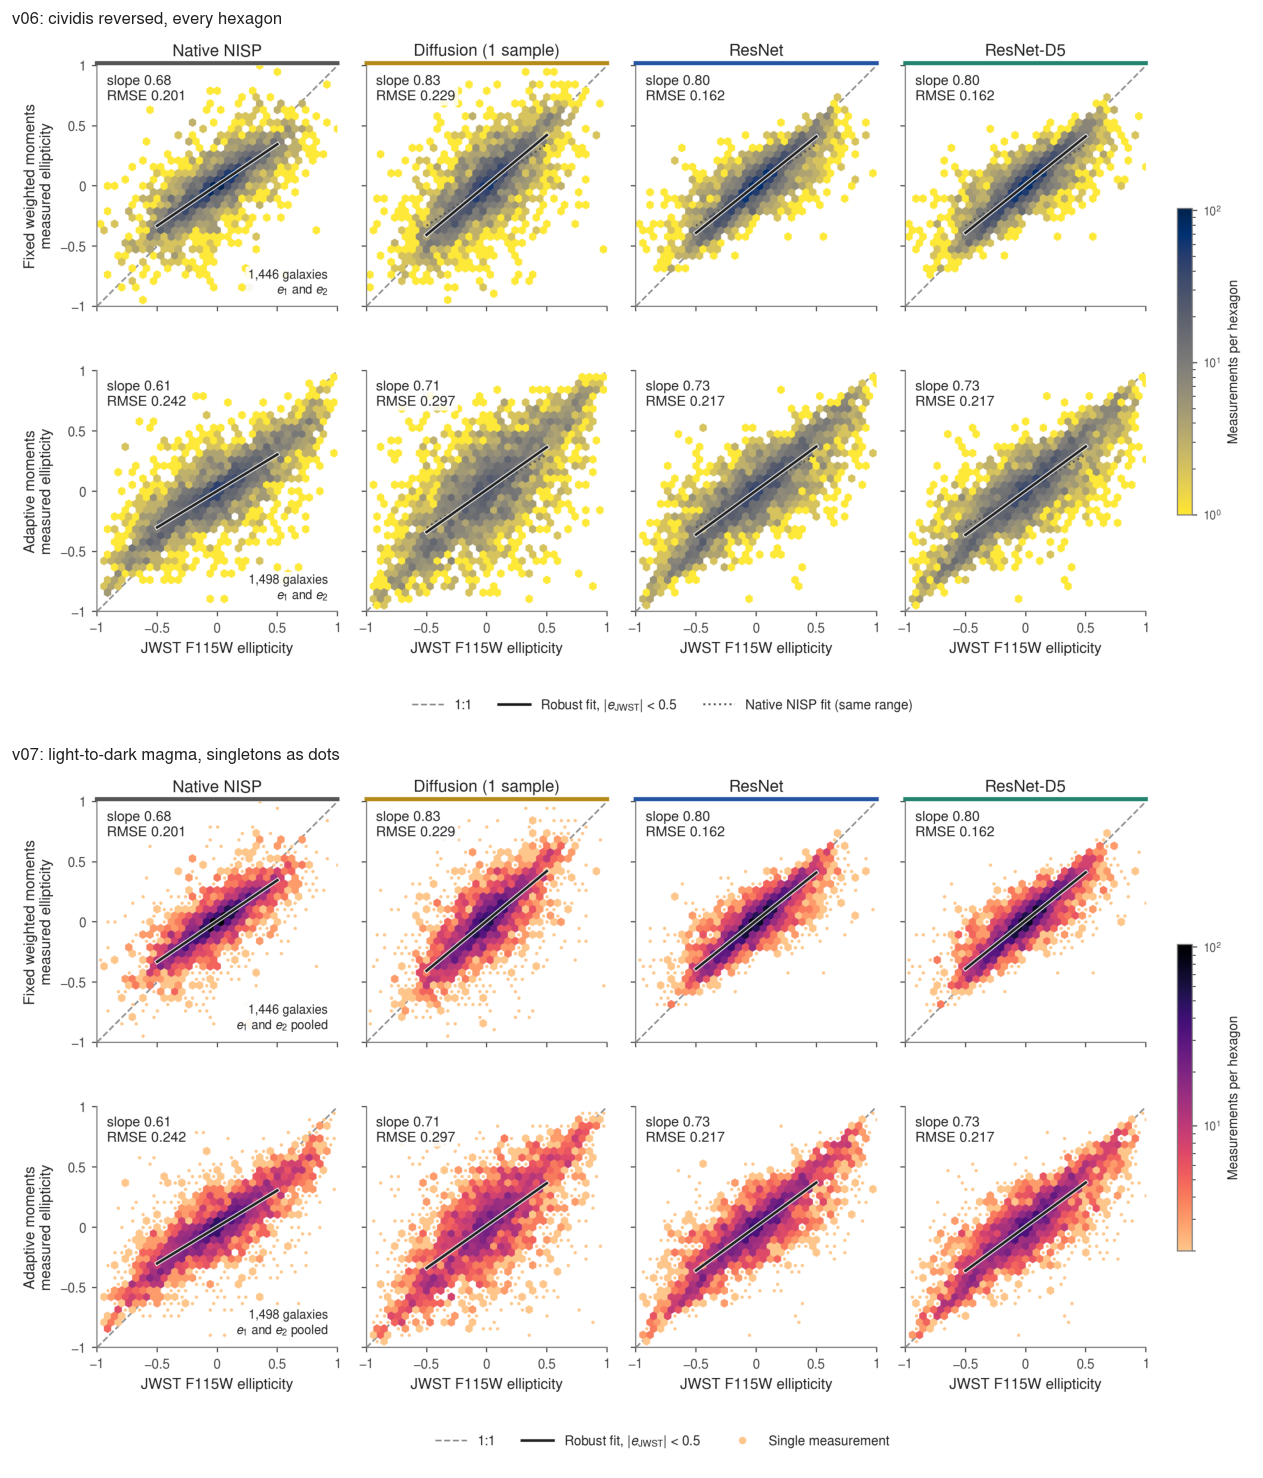

In [3]:
# Main figure: shared logarithmic count scale, pale-to-dark so the dense ridge dominates;
# single measurements are drawn as small pale dots so they stay visible without competing.
style(9)
COUNT_CMAP=LinearSegmentedColormap.from_list('count',plt.get_cmap('magma_r')(np.linspace(.12,1,256)))
SINGLE=COUNT_CMAP(0.0)
fig,axes=plt.subplots(2,4,figsize=(10.6,6.0),sharex=True,sharey=True)
collections=[];singles=0
for r,case in enumerate(['fixed','adaptive']):
    x=arrays[f'{case}__target__e'][samples[case]].ravel()
    for c,name in enumerate(shown):
        ax=axes[r,c];y=arrays[f'{case}__{name}__e'][samples[case]].ravel()
        probe=ax.hexbin(x,y,gridsize=34,extent=(-LIM,LIM,-LIM,LIM),mincnt=1,visible=False)
        offsets=probe.get_offsets()[probe.get_array()==1];probe.remove();singles+=len(offsets)
        ax.scatter(offsets[:,0],offsets[:,1],s=4,color=SINGLE,lw=0,zorder=2)
        collection=ax.hexbin(x,y,gridsize=34,extent=(-LIM,LIM,-LIM,LIM),
            cmap=COUNT_CMAP,mincnt=2,bins='log',linewidths=.2,edgecolors='face',zorder=3)
        collections.append(collection)
        if r==0:ax.plot([0,1],[1.01,1.01],transform=ax.transAxes,
                       color=colors[name],lw=2.5,clip_on=False)
max_count=max(float(h.get_array().max()) for h in collections)
for h in collections:h.set_norm(LogNorm(vmin=2,vmax=max_count))
skeleton(fig,axes,FIT_LABEL,native_reference=False)
fig.legends[0].remove()
handles=[Line2D([],[],color='#8C8C8C',ls='--',lw=1,label='1:1'),Line2D([],[],color=INK,lw=1.6,label=FIT_LABEL),
         Line2D([],[],color=SINGLE,marker='o',ms=3.5,ls='',label='Single measurement')]
fig.legend(handles=handles,loc='lower center',ncol=3,frameon=False,bbox_to_anchor=(.54,-.005))
fig.subplots_adjust(right=.925)
cax=fig.add_axes([.95,.29,.012,.43])
cb=fig.colorbar(collections[0],cax=cax)
cb.set_label('Measurements per hexagon',fontsize=8)
cb.ax.tick_params(labelsize=7)
plt.show()
print('Singleton hexagons drawn as dots:',singles)
export(fig,f'fig07_shape_hexbin_{VERSION}','07_model_shapes.ipynb',[path,ROOT/b['arrays_path']],
       dict(**common_settings,hexbin=dict(gridsize=34,scale='log10 count',mincnt=2,singletons='small pale dots at hexagon centres',native_reference_fit=False,
            shared_vmax=max_count,colormap='magma_r truncated to [0.12,1]')),
       status='Figure 7: unchanged measurements; light-to-dark magma count scale, singletons as dots, pooled-component label, no native reference fit')
style()

# Proof: previous v06 rendering beside the new one.
from matplotlib.image import imread
old_png=FIGURES/'exports'/'fig07_shape_hexbin_v06.png';new_png=FIGURES/'exports'/f'fig07_shape_hexbin_{VERSION}.png'
fig,axes=plt.subplots(2,1,figsize=(10.6,12.4))
for ax,p,t in zip(axes,[old_png,new_png],['v06: cividis reversed, every hexagon','v07: light-to-dark magma, singletons as dots']):
    ax.imshow(imread(p));ax.set_axis_off();ax.set_title(t,loc='left',fontsize=10)
fig.tight_layout();fig.savefig(FIGURES/'exports'/f'fig07_shape_hexbin_{VERSION}_vs_v06.png',dpi=150,facecolor='white');plt.show()


## Figure 7 caption

Density of ellipticity measured on native NISP, a single diffusion sample, ResNet
and ResNet-D5 (columns) against the same measurement on observed JWST F115W,
using fixed weighted moments (top) and adaptive moments (bottom). Hexagonal bins
use a shared logarithmic count scale from light to dark (colorbar), and
isolated single measurements are shown as small pale dots; colored header rules identify
methods consistently with the other figures. Both components
$e_1$ and $e_2$ are counted for every galaxy in each estimator's common
successful sample (1,446 galaxies for fixed moments, 1,498 for adaptive moments,
out of 2,118 attempted validation fields). The dashed line is the 1:1 relation;
the solid line is a robust Theil-Sen fit of measured against JWST ellipticity
over galaxies with $|e_{\rm JWST}|<0.5$, drawn over that range. Each panel lists
the core fit slope and the full-sample RMSE about the 1:1 line, combining both components as
$\sqrt{\langle(\Delta e_1^2+\Delta e_2^2)/2\rangle}$. ResNet and ResNet-D5
steepen the relation towards 1:1 and reduce the scatter relative to native NISP
for both estimators; a single diffusion sample steepens the slope but increases
the scatter. Paired bootstrap intervals on the RMSE reduction are given in the
companion gain figure. These observed cross-band shapes include instrumental PSF
and pixel-sampling differences; they are not calibrated shear estimates.


In [4]:
# Preserve the previously computed bootstrap table; no resampling for a style change.
fit_table_path=FIGURES/'inputs/shape_fit_table_style_v01.json'
fit_table=read_json(fit_table_path)
assert sha(ROOT/fit_table['source_notebook'])==fit_table['source_sha256']
display(pd.DataFrame(fit_table['records']))


,estimator,method,objects,slope,slope_ci95,intercept,rmse,rmse_ci95,gain_percent,gain_ci95_percent
0,fixed,Native NISP,1446,0.678051,"[0.657, 0.7]",0.007689,0.201114,"[0.1941, 0.2069]",0.000000,"[0.0, 0.0]"
1,fixed,Diffusion (1 sample),1446,0.828061,"[0.795, 0.861]",0.008165,0.228958,"[0.2185, 0.2378]",-13.844969,"[-16.03157423277367, -11.26577964635931]"
2,fixed,ResNet,1446,0.799553,"[0.774, 0.827]",0.010122,0.162364,"[0.1549, 0.1684]",19.267582,"[16.591509333536603, 21.87278368654546]"
3,fixed,ResNet-D5,1446,0.801638,"[0.775, 0.829]",0.011399,0.162494,"[0.1547, 0.1687]",19.203084,"[16.520554995929015, 21.64788704880936]"
4,adaptive,Native NISP,1498,0.606793,"[0.583, 0.638]",0.002352,0.242377,"[0.2311, 0.2527]",0.000000,"[0.0, 0.0]"
5,adaptive,Diffusion (1 sample),1498,0.705552,"[0.67, 0.743]",0.013011,0.296577,"[0.2882, 0.3042]",-22.362146,"[-27.807251658056707, -17.97281253539561]"
6,adaptive,ResNet,1498,0.730943,"[0.711, 0.753]",0.005296,0.216657,"[0.2094, 0.2237]",10.611569,"[7.3468183709684, 13.219594509871527]"
7,adaptive,ResNet-D5,1498,0.733850,"[0.71, 0.758]",0.004302,0.216849,"[0.2093, 0.224]",10.532413,"[7.611552589936058, 13.020338502896005]"


## Layout alternatives (not selected)

The hexbin above was chosen as the main figure. A is points only (`fig07_shape_scatter`), B adds 68/95% KDE highest-density contours to faint points (`fig07_shape_contours`), and C shows the regions alone (`fig07_shape_regions`). All share the same samples, robust core fits, RMSE values and axes. Contour regions are joint highest-density regions, not conditional intervals.

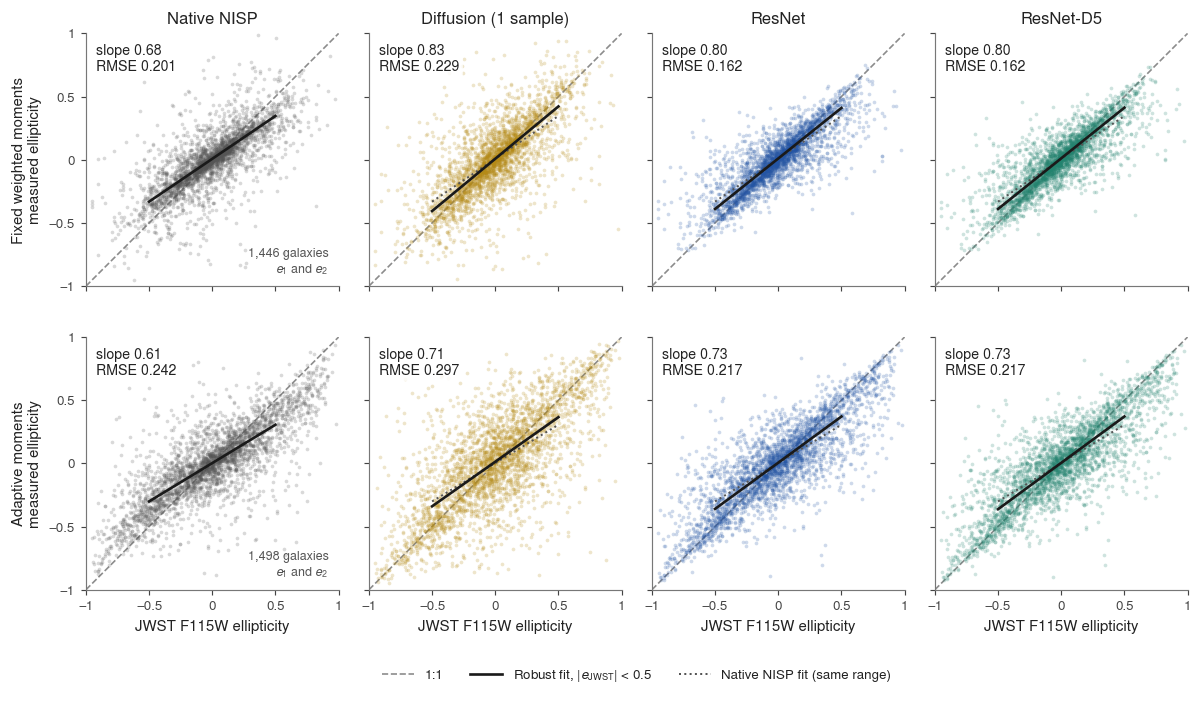

Exported: fig07_shape_scatter_v07.pdf, fig07_shape_scatter_v07.svg, fig07_shape_scatter_v07.png


In [5]:
# Alternative A: points only (previous main figure).
style(9)
fig,axes=plt.subplots(2,4,figsize=(10.2,5.9),sharex=True,sharey=True)
for r,(case,ctitle) in enumerate([('fixed','Fixed weighted moments'),('adaptive','Adaptive moments')]):
    mask=samples[case];x=arrays[f'{case}__target__e'][mask].ravel()
    for c,name in enumerate(shown):
        ax=axes[r,c];y=arrays[f'{case}__{name}__e'][mask].ravel()
        slope,intercept=fits[case,name]
        ax.plot(xx,xx,color='#8C8C8C',lw=1,ls='--',zorder=1)
        ax.scatter(x,y,s=5,color=colors[name],alpha=.22,lw=0,rasterized=True,zorder=2)
        if name!='native':
            sn,inn=fits[case,'native'];ax.plot(xf,sn*xf+inn,color=colors['native'],lw=1.2,ls=':',zorder=3)
        ax.plot(xf,slope*xf+intercept,color='#1A1A1A',lw=1.6,zorder=4)
        ax.text(.04,.96,f'slope {slope:.2f}\nRMSE {rmses[case,name]:.3f}',transform=ax.transAxes,va='top',ha='left',
                fontsize=8.5,bbox=dict(boxstyle='round,pad=.25',fc='white',ec='none',alpha=.85))
        ax.set_xlim(-LIM,LIM);ax.set_ylim(-LIM,LIM);ax.set_aspect('equal')
        ax.set_xticks([-1,-.5,0,.5,1],['−1','−0.5','0','0.5','1']);ax.set_yticks([-1,-.5,0,.5,1],['−1','−0.5','0','0.5','1'])
        if r==0:ax.set_title(titles[name],pad=6)
        if r==1:ax.set_xlabel('JWST F115W ellipticity')
    axes[r,0].set_ylabel(f'{ctitle}\nmeasured ellipticity')
    axes[r,0].text(.96,.04,f'{mask.sum():,} galaxies\n$e_1$ and $e_2$',transform=axes[r,0].transAxes,
                   ha='right',va='bottom',fontsize=7.5,color='#555555')
handles=[Line2D([],[],color='#8C8C8C',ls='--',lw=1,label='1:1'),
         Line2D([],[],color='#1A1A1A',lw=1.6,label='Robust fit, |$e_{\\rm JWST}$| < 0.5'),
         Line2D([],[],color=colors['native'],ls=':',lw=1.2,label='Native NISP fit (same range)')]
fig.legend(handles=handles,loc='lower center',ncol=3,frameon=False,bbox_to_anchor=(.54,-.005))
fig.subplots_adjust(left=.09,right=.99,top=.94,bottom=.135,wspace=.12,hspace=.14)
plt.show()
export(fig,f'fig07_shape_scatter_{VERSION}','07_model_shapes.ipynb',
       [path,ROOT/b['arrays_path']],
       dict(methods=shown,estimators=['fixed','adaptive'],components='e1 and e2 pooled per galaxy',
            fit='Theil-Sen median slope of measured on JWST ellipticity, galaxies with |e_JWST|<0.5',fit_range=[-FIT_RANGE,FIT_RANGE],
            core_points={f'{case}/{name}':core_fit(arrays[f'{case}__target__e'][samples[case]].ravel(),arrays[f'{case}__{name}__e'][samples[case]].ravel())[2] for case in samples for name in shown},
            rmse='combined e1/e2 component RMSE about the 1:1 line',
            common_objects={case:int(samples[case].sum()) for case in samples},
            fits={f'{case}/{name}':dict(slope=float(s),intercept=float(i)) for (case,name),(s,i) in fits.items()},
            axis_limits=[-LIM,LIM],points_outside_axes={f'{case}/{name}':int((np.abs(arrays[f'{case}__{name}__e'][samples[case]])>LIM).sum())
                                                       for case in samples for name in shown},
            population=b['population']),
       status='Figure 7 alternative A: points only')
style()

In [6]:
# KDE highest-density regions for the contour alternatives.
from scipy.stats import gaussian_kde
KDE_GRID=np.linspace(-LIM,LIM,161);KDE_LEVELS=(.95,.68)  # highest-density regions enclosing 95% and 68%
kde={}
for case in samples:
    x=arrays[f'{case}__target__e'][samples[case]].ravel()
    for name in shown:
        y=arrays[f'{case}__{name}__e'][samples[case]].ravel()
        X,Y=np.meshgrid(KDE_GRID,KDE_GRID)
        Z=gaussian_kde(np.c_[x,y].T)(np.c_[X.ravel(),Y.ravel()].T).reshape(X.shape)
        zs=np.sort(Z.ravel())[::-1];cum=np.cumsum(zs)/zs.sum()
        kde[case,name]=(X,Y,Z,[float(zs[np.searchsorted(cum,q)]) for q in KDE_LEVELS])
print('KDE regions ready for',len(kde),'panels')

KDE regions ready for 8 panels


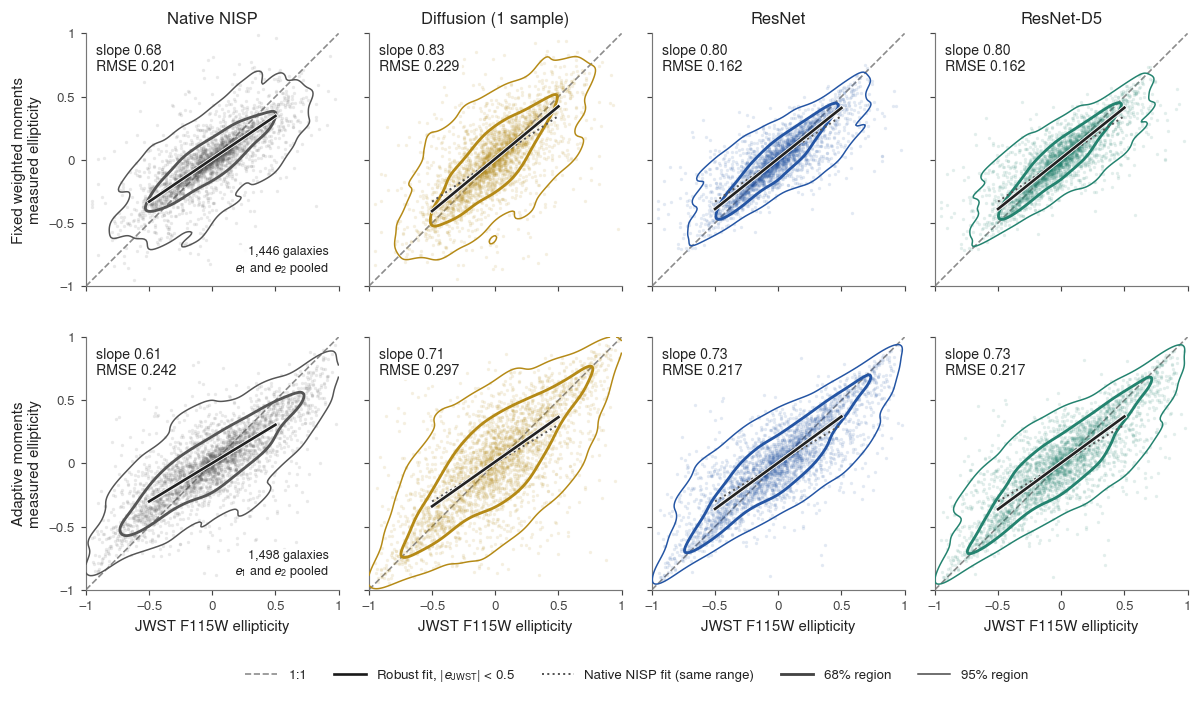

Exported: fig07_shape_contours_v07.pdf, fig07_shape_contours_v07.svg, fig07_shape_contours_v07.png


In [7]:
# Alternative B: faint points plus KDE highest-density contours (68% solid, 95% thin).
style(9)
fig,axes=plt.subplots(2,4,figsize=(10.2,5.9),sharex=True,sharey=True)
for r,case in enumerate(['fixed','adaptive']):
    x=arrays[f'{case}__target__e'][samples[case]].ravel()
    for c,name in enumerate(shown):
        ax=axes[r,c];y=arrays[f'{case}__{name}__e'][samples[case]].ravel()
        ax.scatter(x,y,s=4,color=colors[name],alpha=.13,lw=0,rasterized=True,zorder=2)
        X,Y,Z,lv=kde[case,name]
        ax.contour(X,Y,Z,levels=lv,colors=[colors[name]],linewidths=[.9,1.7],zorder=4)
skeleton(fig,axes,FIT_LABEL)
fig.legends[0].remove()
handles=[Line2D([],[],color='#8C8C8C',ls='--',lw=1,label='1:1'),Line2D([],[],color='#1A1A1A',lw=1.6,label=FIT_LABEL),
         Line2D([],[],color=colors['native'],ls=':',lw=1.2,label='Native NISP fit (same range)'),
         Line2D([],[],color='#444444',lw=1.7,label='68% region'),Line2D([],[],color='#444444',lw=.9,label='95% region')]
fig.legend(handles=handles,loc='lower center',ncol=5,frameon=False,bbox_to_anchor=(.54,-.005))
plt.show()
export(fig,f'fig07_shape_contours_{VERSION}','07_model_shapes.ipynb',[path,ROOT/b['arrays_path']],
       dict(**common_settings,density='Gaussian KDE, Scott bandwidth, 161x161 grid on [-1,1]^2',regions=list(KDE_LEVELS)),
       status='Figure 7 alternative B: points with 68/95% KDE regions')
style()

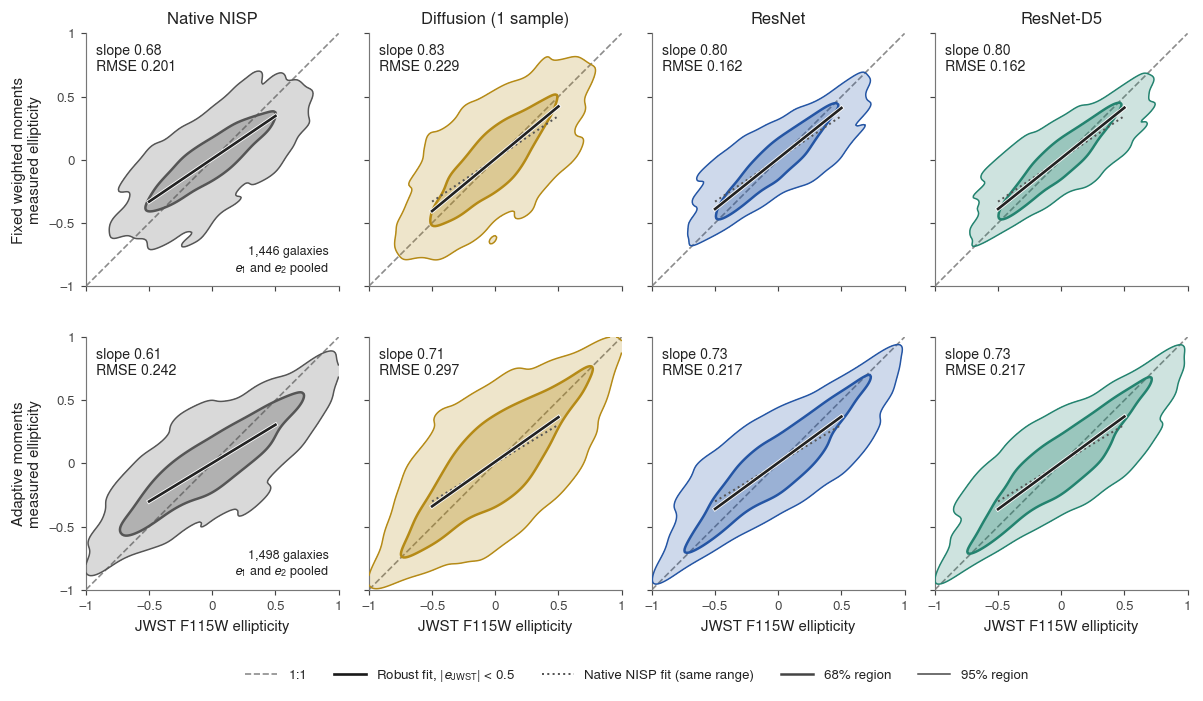

Exported: fig07_shape_regions_v07.pdf, fig07_shape_regions_v07.svg, fig07_shape_regions_v07.png


In [8]:
# Alternative C: KDE regions only (no points); 95% filled, 68% outlined.
style(9)
fig,axes=plt.subplots(2,4,figsize=(10.2,5.9),sharex=True,sharey=True)
for r,case in enumerate(['fixed','adaptive']):
    for c,name in enumerate(shown):
        ax=axes[r,c];X,Y,Z,lv=kde[case,name]
        ax.contourf(X,Y,Z,levels=[lv[0],Z.max()],colors=[colors[name]],alpha=.22,zorder=2)
        ax.contourf(X,Y,Z,levels=[lv[1],Z.max()],colors=[colors[name]],alpha=.30,zorder=3)
        ax.contour(X,Y,Z,levels=lv,colors=[colors[name]],linewidths=[.9,1.5],zorder=4)
skeleton(fig,axes,FIT_LABEL)
fig.legends[0].remove()
handles=[Line2D([],[],color='#8C8C8C',ls='--',lw=1,label='1:1'),Line2D([],[],color='#1A1A1A',lw=1.6,label=FIT_LABEL),
         Line2D([],[],color=colors['native'],ls=':',lw=1.2,label='Native NISP fit (same range)'),
         Line2D([],[],color='#444444',lw=1.5,label='68% region'),Line2D([],[],color='#444444',lw=.9,label='95% region')]
fig.legend(handles=handles,loc='lower center',ncol=5,frameon=False,bbox_to_anchor=(.54,-.005))
plt.show()
export(fig,f'fig07_shape_regions_{VERSION}','07_model_shapes.ipynb',[path,ROOT/b['arrays_path']],
       dict(**common_settings,density='Gaussian KDE, Scott bandwidth, 161x161 grid on [-1,1]^2',regions=list(KDE_LEVELS)),
       status='Figure 7 alternative C: 68/95% KDE regions only')
style()

## Companion: paired RMSE reduction with bootstrap intervals

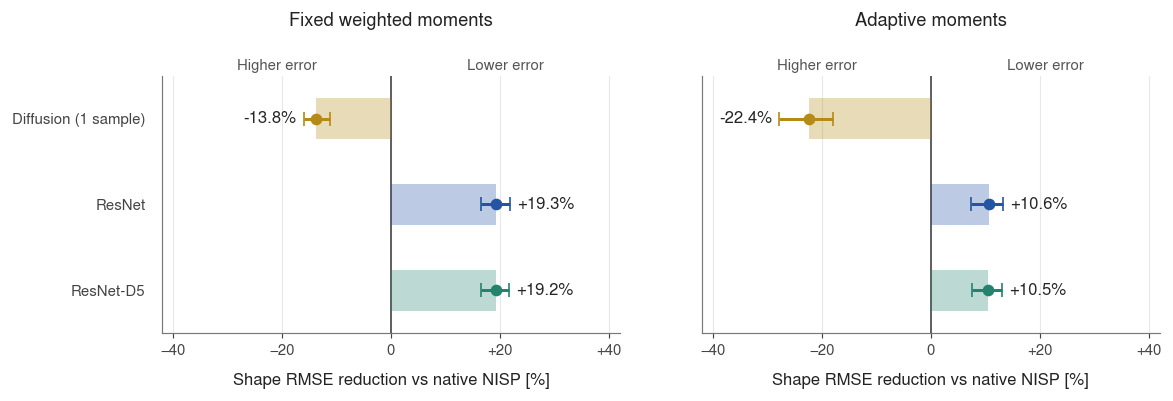

Exported: fig07_shape_improvement_v07.pdf, fig07_shape_improvement_v07.svg, fig07_shape_improvement_v07.png


In [9]:
# Companion: paired RMSE reduction with 95% spatial-block intervals (previous main figure).
style(10)
gain_shown=['diffusion','legacy','direct5']
fig,axes=plt.subplots(1,2,figsize=(10.2,3.7),sharex=True,sharey=True)
y=np.arange(len(gain_shown))
for ax,case,title in zip(axes,['fixed','adaptive'],['Fixed weighted moments','Adaptive moments']):
    ax.axvline(0,color='#555555',lw=1.1,zorder=1)
    ax.grid(axis='x',color='#E8E8E8',lw=.7,zorder=0)
    for i,name in enumerate(gain_shown):
        record=b['native_comparison'][case][name]
        gain=record['reduction_percent'][0]
        lo,hi=record['ci95_percent'][0]
        rmse=b['summaries'][case]['methods'][name]['component_rmse']['mean']
        native_rmse=b['summaries'][case]['methods']['native']['component_rmse']['mean']
        assert np.isclose(gain,100*(1-rmse/native_rmse))
        ax.barh(i,gain,height=.48,color=colors[name],alpha=.30,zorder=2)
        ax.errorbar(gain,i,xerr=[[gain-lo],[hi-gain]],fmt='o',ms=6,
                    color=colors[name],ecolor=colors[name],capsize=4,lw=1.8,zorder=3)
        ax.text(hi+1.3 if gain>=0 else lo-1.3,i,f'{gain:+.1f}%',
                va='center',ha='left' if gain>=0 else 'right',fontsize=10,color='#252525')
    ax.set_title(title,pad=30)
    ax.text(.25,1.025,'Higher error',ha='center',transform=ax.transAxes,fontsize=9,color='#555555')
    ax.text(.75,1.025,'Lower error',ha='center',transform=ax.transAxes,fontsize=9,color='#555555')
    ax.set_xlim(-42,42);ax.set_xticks([-40,-20,0,20,40],['−40','−20','0','+20','+40'])
    ax.set_ylim(len(gain_shown)-.5,-.5)
    ax.set_xlabel('Shape RMSE reduction vs native NISP [%]',labelpad=9)
axes[0].set_yticks(y,[labels[m] for m in gain_shown])
for ax in axes:ax.tick_params(axis='y',length=0,pad=10)
fig.subplots_adjust(left=.17,right=.985,top=.78,bottom=.20,wspace=.18)
plt.show()
export(fig,f'fig07_shape_improvement_{VERSION}','07_model_shapes.ipynb',
       [path,ROOT/b['arrays_path']],
       dict(methods=gain_shown,estimators=['fixed','adaptive'],
            metric='100*(1-RMSE_model/RMSE_native), combined e1/e2 component RMSE',
            intervals=b['gain'],population=b['population'],
            common_objects={case:b['summaries'][case]['common_successes'] for case in ['fixed','adaptive']},
            axis_limits=[-42,42],native_baseline_percent=0),
       status='Companion: paired shape RMSE reduction relative to native NISP')
style()

## Companion diagnostic: both estimators and all attempted measurements

/home/shemmati/.local/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Nimbus Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/shemmati/.local/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Nimbus Sans.
  fig.canvas.print_figure(bytes_io, **kw)


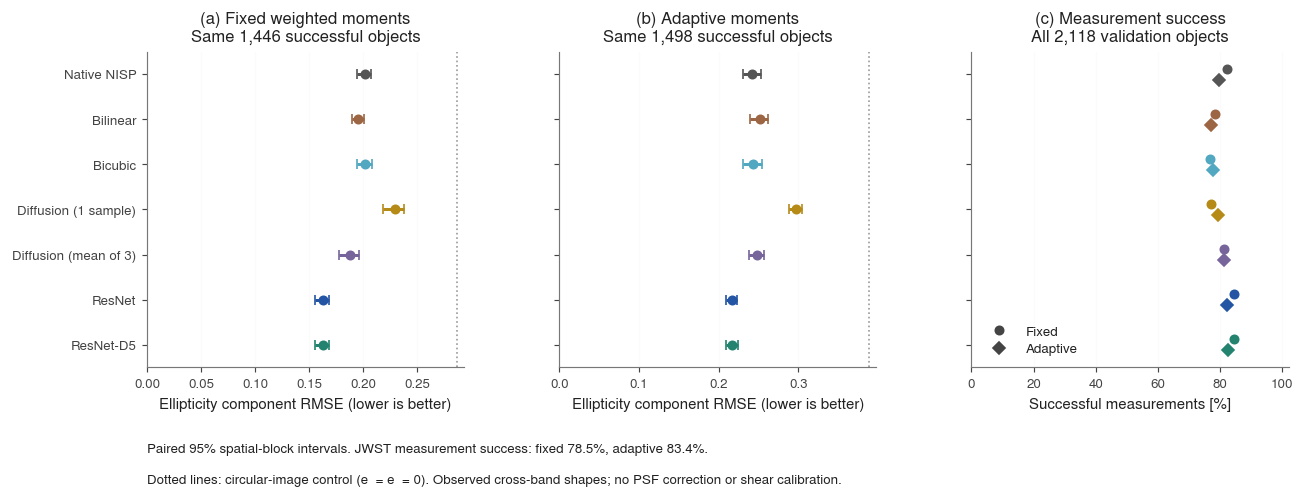

/home/shemmati/Work/Projects/superNISP/paper_figures/figure_utils.py:86: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Nimbus Sans.
  fig.savefig(path,bbox_inches='tight',facecolor='white')
/home/shemmati/Work/Projects/superNISP/paper_figures/figure_utils.py:86: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Nimbus Sans.
  fig.savefig(path,bbox_inches='tight',facecolor='white')


Exported: fig07_model_shapes_v07.pdf, fig07_model_shapes_v07.svg, fig07_model_shapes_v07.png


[PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v07.pdf'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v07.svg'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v07.png')]

In [10]:
fig,axes=plt.subplots(1,3,figsize=(11.6,4.7),sharey=True)
y=np.arange(len(names))
for ax,case,title in zip(axes[:2],['fixed','adaptive'],['(a) Fixed weighted moments','(b) Adaptive moments']):
    summary=b['summaries'][case]
    for i,name in enumerate(names):
        rec=summary['methods'][name]['component_rmse'];value=rec['mean'];lo,hi=rec['ci95']
        ax.errorbar(value,i,xerr=np.array([[value-lo],[hi-value]]),fmt='o',color=colors[name],capsize=3,ms=5)
    control=summary['methods']['round_control']['component_rmse']['mean']
    ax.axvline(control,color='#999999',ls=':',lw=1)
    ax.set_xlim(left=0)
    ax.set_xlabel('Ellipticity component RMSE (lower is better)')
    ax.set_title(f"{title}\nSame {summary['common_successes']:,} successful objects")
axes[0].set_yticks(y,[labels[m] for m in names])
for case,marker,offset in [('fixed','o',-.12),('adaptive','D',.12)]:
    for i,name in enumerate(names):
        fraction=100*b['summaries'][case]['success_counts'][name]/len(b['object_ids'])
        axes[2].plot(fraction,i+offset,marker,color=colors[name],ms=5)
axes[2].set_title('(c) Measurement success\nAll 2,118 validation objects')
axes[2].set_xlim(0,102);axes[2].set_xlabel('Successful measurements [%]')
axes[2].legend(handles=[Line2D([],[],color='#444444',marker='o',ls='',label='Fixed'),Line2D([],[],color='#444444',marker='D',ls='',label='Adaptive')],loc='lower left',frameon=False)
for ax in axes:
    ax.set_ylim(len(names)-.5,-.5);ax.grid(axis='x',alpha=.15)
fig.subplots_adjust(left=.17,right=.99,top=.81,bottom=.25,wspace=.3)
fixed_ref=100*b['summaries']['fixed']['success_counts']['target']/len(b['object_ids'])
adaptive_ref=100*b['summaries']['adaptive']['success_counts']['target']/len(b['object_ids'])
fig.text(.17,.10,f'Paired 95% spatial-block intervals. JWST measurement success: fixed {fixed_ref:.1f}%, adaptive {adaptive_ref:.1f}%.',fontsize=8)
fig.text(.17,.045,'Dotted lines: circular-image control (e₁ = e₂ = 0). Observed cross-band shapes; no PSF correction or shear calibration.',fontsize=8)
plt.show()
export(fig,f'fig07_model_shapes_{VERSION}','07_model_shapes.ipynb',[path],
       dict(population=b['population'],fixed=b['fixed'],adaptive=b['adaptive'],summary=b['summary']),
       status='Local matched observed-shape comparison and full-denominator measurement success')


In [11]:
rows=[]
for population,summaries in [('Per-estimator common',b['summaries']),('Both estimators common',b['cross_estimator_common'])]:
    for estimator,summary in summaries.items():
        for name in names:
            rec=summary['methods'][name]
            rows.append(dict(population=population,estimator=estimator,objects=summary['common_successes'],method=labels[name],
                component_rmse=rec['component_rmse']['mean'],ci95=rec['component_rmse']['ci95'],bias_e1=rec['bias']['mean'][0],bias_e2=rec['bias']['mean'][1],
                large_error_fraction=rec['vector_error_above_0_2_fraction']['mean']))
display(pd.DataFrame(rows))


,population,estimator,objects,method,component_rmse,ci95,bias_e1,bias_e2,large_error_fraction
0,Per-estimator common,fixed,1446,Native NISP,0.201114,"[0.19428294814922256, 0.2071313152267453]",0.011173,-0.000405,0.376902
1,Per-estimator common,fixed,1446,Bilinear,0.195218,"[0.1892041880685358, 0.2004383864028548]",0.010785,0.000455,0.399723
2,Per-estimator common,fixed,1446,Bicubic,0.201446,"[0.19418894795282546, 0.2078456160897296]",0.010564,-0.000530,0.374827
3,Per-estimator common,fixed,1446,Diffusion (1 sample),0.228958,"[0.2184291798724818, 0.23781131310163514]",0.032180,-0.015698,0.429461
4,Per-estimator common,fixed,1446,Diffusion (mean of 3),0.187511,"[0.17752315863011217, 0.19618020484332216]",0.031907,-0.015020,0.352006
5,Per-estimator common,fixed,1446,ResNet,0.162364,"[0.15529346190828233, 0.16839012022839078]",0.017356,-0.000945,0.286307
6,Per-estimator common,fixed,1446,ResNet-D5,0.162494,"[0.1554486054894158, 0.16864597053879055]",0.019325,-0.000040,0.286307
7,Per-estimator common,adaptive,1498,Native NISP,0.242377,"[0.23029156356561614, 0.2531584123270412]",0.010843,-0.006433,0.550734
8,Per-estimator common,adaptive,1498,Bilinear,0.251618,"[0.23924230763094992, 0.2620319609871056]",0.012356,-0.003585,0.598798
9,Per-estimator common,adaptive,1498,Bicubic,0.243203,"[0.23100338883495103, 0.25406251889347065]",0.010900,-0.006499,0.560748


## Interpretation limits

The error bars condition on each estimator's matched successful sample. Report
full-population success fractions with the shape errors, and inspect the stricter
intersection across both estimators. Fixed and adaptive shapes use different
weights, so their absolute RMSE values have different targets. Galaxies in a
blend may contaminate both measurements; the adaptive centroid guard is not a
deblender. Mean-of-three refers to a mean image, not averaged ellipticity draws.
This cache cannot establish diffusion realization-to-realization shape scatter.
